# Servicios para adultos mayores en la CDMX: proyección a 2031
### Versión ejecutiva

Proyección de la población de 60 y más y de los asilos (SCIAN 623311 y 623312) en la Ciudad de México,
a partir del Censo 2010, la Encuesta Intercensal 2015 y el Censo 2020 a nivel AGEB, cruzados con el
DENUE.

> Esta versión contiene el camino mínimo de datos a conclusiones. La evidencia que justifica cada
> decisión —autocorrelación espacial, backtest completo de métodos de proyección, comparación de
> modelos de conteo, validación cruzada espacial de los niveles de agrupación, la accesibilidad por
> radio que se descartó y las aperturas netas por alcaldía— está en **`analisis_completo.ipynb`**. Los resultados son
> idénticos; lo que falta aquí es el trabajo de mostrarlos.

---

## Resumen

| Pregunta | Respuesta | Confianza |
|---|---|---|
| ¿Cuánta población de 60+ habrá en 2031? | 2.1-2.4 millones (+43 a +58% sobre 2020) | **Alta** — backtest R² 0.94, MAPE 10% |
| ¿Cuántos asilos habrá en 2031? | 124 esperados, intervalo al 90% [95, 157], contra 109 hoy | **Media** — la dirección sí, la magnitud no |
| ¿Cuántos asilos habrá en un AGEB dado? | No es respondible con estos datos | **Nula** — se documenta por qué |
| ¿Dónde está el desajuste? | 752 mil personas 60+ nuevas sobre 108 asilos; 6.6x de diferencia entre alcaldías | **Alta** — es aritmética, sin supuestos de distancia |

**El hallazgo de fondo:** la elasticidad oferta-población es **0.51**, no 1. La oferta crece a poco más
de la mitad del ritmo de la demanda demográfica, y además se ubica donde *estuvo* la demanda y no donde
va a estar: los asilos se apiñan en el centro-poniente mientras el crecimiento de población mayor se
concentra en la periferia sur y oriente. La brecha de 2031 no es un problema de cantidad, es de
territorio.

**Advertencia de lectura:** todo lo que sigue proyecta el comportamiento observado del mercado. Es
"cuántos habrá si nada cambia", nunca "cuántos se necesitan" — no existe en México un estándar
normativo de camas por cada mil adultos mayores contra el cual medir suficiencia.

**Cómo está organizado:** 1) EDA · 2) proyección de población · 3) cuántos asilos · 4) dónde ·
5) conclusiones. El análisis cierra en **§4**, con el desajuste entre dónde está la oferta y dónde
crece la demanda.

---

## Requisitos

Python **3.11 o 3.12** (con 3.13/3.14 PyMC y PyTensor todavía fallan):

```bash
python3.11 -m venv .venv
source .venv/bin/activate          # en Windows: .venv\Scripts\activate
pip install -r requirements.txt
python -m ipykernel install --user --name inegi --display-name "Python (inegi)"
```

Entradas: `datos/results{2010,2015,2020}.csv` y `geo/2020_1_09_A.shp`. Si PyMC no compila —frecuente en
macOS con Apple Silicon— la sección 3.2 cae sola a una aproximación variacional y el resto corre igual.

## 1. EDA

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm, statsmodels.formula.api as smf
from scipy import stats
from scipy.spatial import cKDTree
from matplotlib.patches import Patch

DATOS, GEO, FIG = Path("datos"), Path("geo"), Path("figuras"); FIG.mkdir(exist_ok=True)
SERV = ["cantidad_serv_enf_dom", "cantidad_asilos"]
SEMILLA = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"grid.alpha": .25, "axes.edgecolor": "#BBB", "figure.dpi": 110, "font.size": 9})
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40)

def cargar(anio):
    # cvegeo como TEXTO: son 13 caracteres y algunos terminan en letra (090020001003A)
    df = pd.read_csv(DATOS/f"results{anio}.csv",
                     dtype={"cvegeo": str, "ageb": str, "entidad": str, "mun": str, "loc": str})
    df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])
    df["anio"] = anio
    df["p60"] = df["p_60ymas_est"] if "p_60ymas_est" in df.columns else df["p_60ymas"]  # 2015 es encuesta
    return df[["cvegeo", "nom_mun", "anio", "p60"] + SERV]

panel = pd.concat([cargar(a) for a in (2010, 2015, 2020)], ignore_index=True)
ult = panel[panel.anio == 2020].copy()

# Cortes adicionales del DENUE (solo oferta): amplían la serie a seis puntos
ofer = panel.pivot_table(index="cvegeo", columns="anio", values=SERV[1], aggfunc="sum").fillna(0)
enfe = panel.pivot_table(index="cvegeo", columns="anio", values=SERV[0], aggfunc="sum").fillna(0)
for a in (2018, 2023, 2025):
    d = pd.read_csv(DATOS/f"datos_denue_{a}.csv", dtype={"cvegeo": str}).fillna(0).set_index("cvegeo")
    ofer[a] = d[SERV[1]].reindex(ofer.index).fillna(0)
    enfe[a] = d[SERV[0]].reindex(enfe.index).fillna(0)
ANIOS_OF = sorted(ofer.columns); ofer, enfe = ofer[ANIOS_OF], enfe[ANIOS_OF]

geo = gpd.read_file(GEO/"2020_1_09_A.shp")[["CVEGEO", "geometry"]].rename(columns={"CVEGEO": "cvegeo"})
anchos = panel.pivot_table(index="cvegeo", columns="anio", values="p60")
anchos.columns = [f"p60_{c}" for c in anchos.columns]
gg = (geo.merge(anchos, on="cvegeo", how="inner")
         .merge(ult[["cvegeo", "nom_mun"] + SERV], on="cvegeo", how="left")).reset_index(drop=True)
gg["area_km2"] = gg.area/1e6
gg["dens60"] = gg.p60_2020/gg.area_km2
gg["cagr"] = np.where((gg.p60_2010 > 0) & (gg.p60_2020 > 0), (gg.p60_2020/gg.p60_2010)**.1 - 1, np.nan)

print(panel.groupby("anio").agg(agebs=("cvegeo", "nunique"), pob60=("p60", "sum"),
                                enfermeria=(SERV[0], "sum"), asilos=(SERV[1], "sum")).to_string())
print("\nSerie de oferta con los seis cortes del DENUE:")
print(pd.DataFrame({"asilos": ofer.sum(), "enfermeria": enfe.sum(),
                    "AGEBs con asilo": (ofer > 0).sum()}).T.to_string())
print(f"Cruce con la cartografía: {len(gg):,} de {ult.cvegeo.nunique():,} AGEBs")

      agebs         pob60  enfermeria  asilos
anio                                         
2010   2432  1.001814e+06        17.0    78.0
2015   2433  1.273659e+06        26.0    79.0
2020   2433  1.487004e+06        12.0   108.0

Serie de oferta con los seis cortes del DENUE:
anio             2010  2015  2018   2020   2023   2025
asilos           78.0  79.0  87.0  108.0  108.0  109.0
enfermeria       17.0  26.0  26.0   12.0   13.0    8.0
AGEBs con asilo  69.0  69.0  75.0   95.0   94.0   97.0
Cruce con la cartografía: 2,426 de 2,433 AGEBs


**La oferta es minúscula y dejó de crecer.** La serie es **78 → 79 → 87 → 108 → 108 → 109** entre 2010
y 2025: creció 38% en la primera década y se detuvo después de 2020 —un establecimiento neto en cinco
años— mientras la población de 60 y más crecía 20%. Más del 95% de los AGEBs tienen cero. No es un problema de elegir bien el modelo, es cuántos eventos hay
para estimar cualquier cosa. De ahí salen dos decisiones que se arrastran por todo el análisis:

- **La enfermería a domicilio no se modela.** Su serie completa es 17 → 26 → 26 → 12 → 13 → 8: sube,
  se congela, se derrumba y vuelve a caer. Su autocorrelación espacial es indistinguible de ruido
  (I de Moran = −0.005, p = 0.37) y el AGEB es la unidad equivocada para un servicio *a domicilio*.
- **Los cortes del DENUE no son plenamente comparables.** El salto de 2018 a 2020 (+21) y la quietud
  de 2020 a 2023 (cero neto) sugieren reclasificación o re-geocodificación. Por eso el modelo de la
  sección 3 lleva un **efecto por corte**, que absorbe esas diferencias de nivel en vez de confundirlas
  con crecimiento.

La población, en cambio, sí tiene estructura fuerte: de 1.00 a 1.49 millones entre 2010 y 2020
(+48.4%), con autocorrelación espacial alta (I de Moran 0.34-0.45) y **clusters de crecimiento en la
periferia sur y poniente** contra la ciudad central estancada. Los mapas lo muestran directamente.

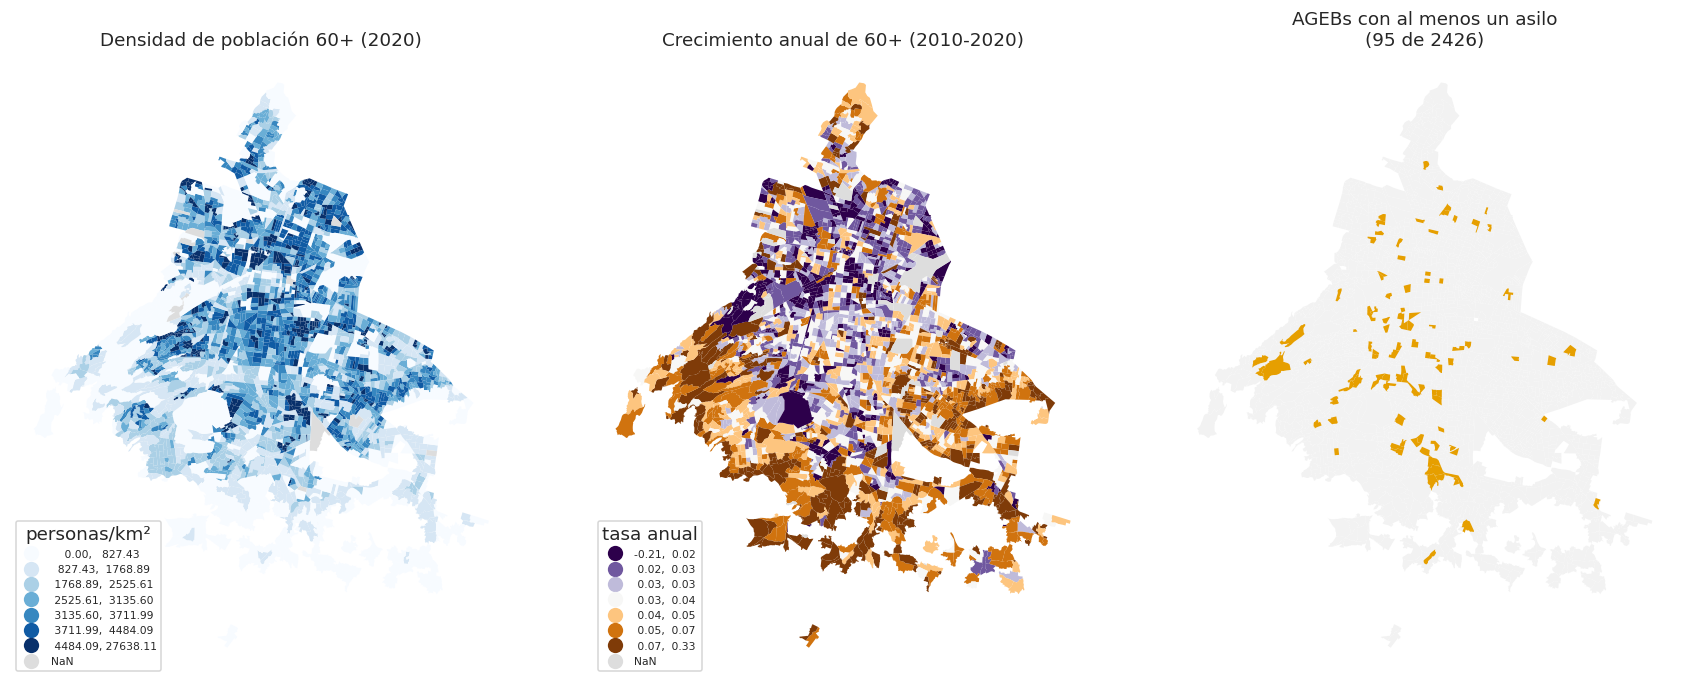

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(16, 6.2))
gg.plot(column="dens60", scheme="quantiles", k=7, cmap="Blues", ax=ax[0], legend=True,
        edgecolor="none", missing_kwds={"color": "#DDD"},
        legend_kwds={"fontsize": 7, "loc": "lower left", "title": "personas/km²"})
ax[0].set_title("Densidad de población 60+ (2020)")
gg.plot(column="cagr", scheme="quantiles", k=7, cmap="PuOr_r", ax=ax[1], legend=True,
        edgecolor="none", missing_kwds={"color": "#DDD"},
        legend_kwds={"fontsize": 7, "loc": "lower left", "title": "tasa anual"})
ax[1].set_title("Crecimiento anual de 60+ (2010-2020)")
gg.plot(color="#F2F2F2", edgecolor="white", linewidth=.05, ax=ax[2])
con_asilo = gg[gg.cantidad_asilos > 0]
con_asilo.plot(ax=ax[2], color="#E69F00", edgecolor="none")
ax[2].set_title(f"AGEBs con al menos un asilo\n({len(con_asilo)} de {len(gg)})")
for a_ in ax: a_.set_axis_off()
plt.tight_layout(); plt.savefig(FIG/"poblacion_y_oferta.png", dpi=150, bbox_inches="tight"); plt.show()

El contraste ya se ve a simple vista: la densidad de población mayor es alta en la ciudad central, pero
**el crecimiento está en la periferia**, y los asilos se concentran justo donde la población ya está, no
donde va a estar. Todo el análisis que sigue es esa observación, cuantificada.

## 2. Proyección de población

Con tres puntos en el tiempo no hay serie que extrapolar por AGEB, así que la pregunta real es **qué
tasa de crecimiento aplicarle a cada uno**. Se decide con backtest: usar 2010 y 2015 para predecir 2020,
el único año verificable.

Gana **encoger la tasa de cada AGEB hacia la de su alcaldía**:

$$r_i = \lambda \, r_i^{\text{AGEB}} + (1-\lambda) \, r_{j(i)}^{\text{alcaldía}}$$

Funciona porque los AGEBs chicos tienen tasas volátiles por puro ruido de conteo (Spearman −0.345 entre
tamaño y |CAGR|) y mezclarlas con la de su alcaldía las estabiliza. El λ óptimo es 0.6 y la curva es
plana entre 0.5 y 0.7: lo que importa es encoger algo, no el valor exacto.

In [3]:
w = panel.pivot_table(index="cvegeo", columns="anio", values="p60").dropna()
w = w[(w > 0).all(axis=1)]
mun_de = ult.set_index("cvegeo").nom_mun
real = w[2020]
tot = pd.DataFrame({"mun": mun_de}).join(w).dropna().groupby("mun")[[2010, 2015, 2020]].sum()
r_ageb = (w[2015]/w[2010])**.2 - 1
r_alc = w.index.to_series().map(mun_de).map((tot[2015]/tot[2010])**.2 - 1)

def error(pred, nombre):
    e, ape = pred - real, np.abs(pred - real)/real
    return dict(metodo=nombre, MAPE=100*np.median(ape), RMSE=np.sqrt(np.mean(e**2)),
                R2=1 - np.sum(e**2)/np.sum((real - real.mean())**2))

print("Backtest — predecir 2020 desde 2010 y 2015:")
print(pd.DataFrame([error(w[2015]*(1 + .5*r_ageb + .5*r_alc)**5, "CAGR encogido 50% a la alcaldía"),
                    error(w[2015]*(1 + r_ageb)**5, "CAGR propio del AGEB"),
                    error(w[2015].astype(float), "Sin cambio (ingenuo)")
                    ]).set_index("metodo").round(3).to_string())

# Tres escenarios: el crecimiento se desaceleró entre quinquenios, así que se acota por ambos lados.
r_rec, r_full = (w[2020]/w[2015])**.2 - 1, (w[2020]/w[2010])**.1 - 1
ra = w.index.to_series().map(mun_de)
ra_rec, ra_full = ra.map((tot[2020]/tot[2015])**.2 - 1), ra.map((tot[2020]/tot[2010])**.1 - 1)
ESCENARIOS = {"bajo": .5*r_rec + .5*ra_rec,
              "medio": .25*(r_rec + r_full) + .25*(ra_rec + ra_full),
              "alto": .5*r_full + .5*ra_full}

proy = pd.DataFrame({e: [w[2020].sum()] + [(w[2020]*(1 + r)**h).sum() for h in (7, 9, 11)]
                     for e, r in ESCENARIOS.items()}, index=[2020, 2027, 2029, 2031])
print("\nPoblación de 60 y más proyectada (miles):")
print((proy/1000).round(0).to_string())
print("\ncrecimiento 2020→2031:",
      {e: f"{100*(proy.loc[2031, e]/proy.loc[2020, e] - 1):.1f}%" for e in ESCENARIOS})

pm_ = pd.DataFrame({"mun": mun_de, "p2020": w[2020],
                    "p2031": w[2020]*(1 + ESCENARIOS["medio"])**11}).groupby("mun").sum()/1000
pm_["cambio_%"] = (100*(pm_.p2031/pm_.p2020 - 1)).round(1)
print("\nPor alcaldía, escenario medio (miles de personas):")
print(pm_.sort_values("cambio_%", ascending=False).round(1).to_string())

Backtest — predecir 2020 desde 2010 y 2015:
                                   MAPE     RMSE     R2
metodo                                                 
CAGR encogido 50% a la alcaldía  10.074   85.844  0.941
CAGR propio del AGEB             11.527   95.941  0.926
Sin cambio (ingenuo)             13.955  121.404  0.882

Población de 60 y más proyectada (miles):
        bajo   medio    alto
2020  1487.0  1487.0  1487.0
2027  1865.0  1924.0  1986.0
2029  1993.0  2074.0  2161.0
2031  2132.0  2238.0  2353.0

crecimiento 2020→2031: {'bajo': '43.4%', 'medio': '50.6%', 'alto': '58.3%'}

Por alcaldía, escenario medio (miles de personas):
                        p2020  p2031  cambio_%
mun                                           
Cuajimalpa de Morelos    25.5   50.9      99.8
Milpa Alta               14.7   27.2      84.6
Tláhuac                  45.7   81.2      77.8
Xochimilco               60.0  104.2      73.7
Tlalpan                 107.5  177.3      64.9
La Magdalena Contreras   38.0 

**Cuajimalpa +100%, Milpa Alta +85%, Tláhuac +78%** contra +35% en Cuauhtémoc. El envejecimiento se está
mudando a la periferia. Este es el insumo que alimenta tanto el modelo de conteo como el análisis
territorial — y, como se verá, es el eslabón fuerte de toda la cadena.

## 3. ¿Cuántos asilos habrá?

Se ajustan dos modelos y hacen cosas distintas:

| | modelo | papel en el análisis |
|---|---|---|
| **El que da la cifra** | **Binomial negativa** (§3.1) | Produce el total proyectado y su intervalo. Es el número que se reporta. |
| **La verificación** | **Jerárquico por regiones** (§3.2) | Vuelve a estimar el mismo total por un camino independiente, y estima la estructura territorial que usa la sección 4. |
| Descartado | Poisson simple | Subestima la varianza y da intervalos falsamente angostos (§3.3). |

**El modelo principal es una binomial negativa**, no una Poisson. La confusión es fácil porque la
binomial negativa *es* una Poisson con un parámetro extra de dispersión, y porque el jerárquico usa
verosimilitud Poisson — pero la cifra viene de la binomial negativa.

### 3.1 El modelo que da la cifra: binomial negativa

Se ajusta **por AGEB** —la máxima resolución— y **sobre los seis cortes del DENUE a la vez**:

$$\log \mu_{it} = \alpha + \beta \log(\text{pob60}_{it}) + \gamma \log(\text{área}_i) + \tau_t$$

Cada fila del panel es un par (AGEB, corte): 2,396 × 6 ≈ 14 mil observaciones con 568 asilos-corte,
contra las 108 de una sola sección transversal. Tres detalles que importan:

- `log(área)` entra porque sin ella la elasticidad se infla, al absorber el efecto mecánico de que en
  los AGEBs grandes caben más establecimientos.
- **$\tau_t$, un efecto fijo por corte**, absorbe las diferencias de nivel entre extracciones del DENUE
  —el salto de 2018 a 2020, la quietud de 2020 a 2023— para que no se confundan con respuesta a la
  población.
- **Errores estándar agrupados por AGEB**, porque los seis cortes son en buena medida los mismos
  establecimientos medidos otra vez; tratarlos como independientes daría intervalos falsamente
  angostos.
- **Binomial negativa y no Poisson.** El índice varianza/media del panel es 1.26 y el AIC lo confirma
  (4,615 contra 4,751). Con Poisson el total de 2031 sale casi igual (123 contra 124) pero con un
  intervalo 14% más angosto, y ese intervalo sería falso.

Para 2018, 2023 y 2025 la población se estima con el método de la sección 2, lo que atenúa β levemente
hacia cero. β es una **elasticidad**: el porcentaje en que crece la oferta esperada cuando la población
crece 1%.

In [4]:
mod = gg[(gg.p60_2020 > 0) & gg.p60_2020.notna() & gg.nom_mun.notna()].reset_index(drop=True).copy()
mod["asilos"] = mod.cantidad_asilos.fillna(0).astype(int)
mod["asilos_2025"] = mod.cvegeo.map(ofer[2025]).fillna(0).astype(int)
mod["lp60"], mod["larea"] = np.log(mod.p60_2020), np.log(mod.area_km2)

# panel largo: un renglón por (AGEB, corte). Población observada en 2010/2015/2020, estimada en el resto
POB = pd.DataFrame(index=mod.cvegeo)
POB[2010], POB[2015], POB[2020] = mod.p60_2010.values, mod.p60_2015.values, mod.p60_2020.values
POB[2018] = POB[2015]*(POB[2020]/POB[2015])**(3/5)
r_med = mod.cvegeo.map(ESCENARIOS["medio"]).fillna(0).values
POB[2023], POB[2025] = POB[2020].values*(1 + r_med)**3, POB[2020].values*(1 + r_med)**5
POB = POB[ANIOS_OF]
pnl = pd.concat([pd.DataFrame({
    "cvegeo": mod.cvegeo, "anio": a, "asilos": mod.cvegeo.map(ofer[a]).fillna(0).astype(int).values,
    "p60": POB[a].values, "area_km2": mod.area_km2.values, "nom_mun": mod.nom_mun.values})
    for a in ANIOS_OF], ignore_index=True)
pnl = pnl[pnl.p60 > 0].copy()
pnl["lp60"], pnl["larea"] = np.log(pnl.p60), np.log(pnl.area_km2)

FORM = "asilos ~ lp60 + larea + C(anio)"
pois = smf.glm(FORM, pnl, family=sm.families.Poisson()).fit()
mu0 = pois.fittedvalues
aux = sm.OLS(((pnl.asilos - mu0)**2 - pnl.asilos)/mu0, mu0).fit()
ALPHA = max(float(aux.params.iloc[0]), 1e-3)
nb = smf.glm(FORM, pnl, family=sm.families.NegativeBinomial(alpha=ALPHA)).fit(
    cov_type="cluster", cov_kwds={"groups": pnl.cvegeo})

print(f"panel: {len(pnl):,} filas ({pnl.cvegeo.nunique():,} AGEBs × {len(ANIOS_OF)} cortes) | "
      f"{pnl.asilos.sum():.0f} asilos-corte")
print(f"alpha = {ALPHA:.3f} | AIC: Poisson {pois.aic:.1f} vs NegBin {nb.aic:.1f}\n")
print(pd.DataFrame({"coef": nb.params, "EE_cluster": nb.bse, "IC_lo": nb.params - 1.96*nb.bse,
                    "IC_hi": nb.params + 1.96*nb.bse, "p": nb.pvalues}).round(3).to_string())

panel: 14,366 filas (2,396 AGEBs × 6 cortes) | 568 asilos-corte
alpha = 4.759 | AIC: Poisson 4751.3 vs NegBin 4614.8

                  coef  EE_cluster  IC_lo  IC_hi      p
Intercept       -5.817       1.346 -8.454 -3.179  0.000
C(anio)[T.2015] -0.120       0.107 -0.331  0.090  0.263
C(anio)[T.2018] -0.075       0.113 -0.298  0.147  0.505
C(anio)[T.2020]  0.094       0.125 -0.151  0.338  0.454
C(anio)[T.2023]  0.037       0.136 -0.230  0.304  0.785
C(anio)[T.2025]  0.003       0.151 -0.294  0.299  0.985
lp60             0.508       0.208  0.101  0.915  0.014
larea            0.478       0.095  0.291  0.665  0.000


**La elasticidad es 0.51, con intervalo de 95% de [0.10, 0.92].** Por cada 10% más de población mayor,
la oferta esperada crece 5.1%. Que β sea menor que 1 es el resultado sustantivo del análisis: **la
brecha se ensancha sola con el tiempo**, sin que nada tenga que empeorar.

Con un solo corte el coeficiente era 0.558 y el intervalo llegaba hasta 0.92 incluyendo el 1; con el
panel de seis cortes el coeficiente casi no se mueve pero **el intervalo ya excluye β = 1**, aunque por
poco. Que la relación sea estable a lo largo de quince años es una señal de que la especificación es
razonable.

### 3.2 La verificación independiente: el modelo jerárquico

La binomial negativa da el total de la ciudad. El jerárquico responde otra cosa: **cuánta
heterogeneidad territorial hay que la población y el área no explican**.

$$\log \mu_{ij} = \alpha_j + \beta \tilde{x}_{ij} + \gamma \tilde{a}_{ij}, \qquad
\alpha_j = \mu_\alpha + \sigma_\alpha z_j$$

Los efectos fijos no sirven: Venustiano Carranza y Milpa Alta tienen **cero** asilos, y un efecto fijo
les daría tasa cero o quedaría no identificado. El *partial pooling* les asigna una tasa baja pero
plausible — la misma idea del encogimiento de la sección 2.

**El nivel de agrupación está decidido con evidencia.** Se compararon seis niveles con validación
cruzada espacial por bloques, y gana **Ward k=40** (regiones contiguas de AGEBs) sobre alcaldías y sobre
particiones más finas: log-score −0.1800 contra −0.1857 de alcaldía, AUC 0.648 contra 0.610, y mejor
calibración del total. El LOO, en cambio, prefiere monótonamente lo más fino y engaña con efectos
espaciales. Se ajusta también por alcaldía, pero como **lectura administrativa**, no como el modelo.

**Y este modelo no compite con la binomial negativa, la contiene:** si σ_α fuera cero serían idénticos.
Lo que cambia es qué hace cada uno con la sobredispersión — ruido sin estructura en uno, territorio en
el otro. **La binomial negativa se usa para el total; el jerárquico, para la estructura territorial.**

In [5]:
import arviz as az
from sklearn.cluster import AgglomerativeClustering
from libpysal.weights import Queen, KNN
from libpysal.weights.util import attach_islands

# Regiones Ward k=40: agregados CONTIGUOS de AGEBs (el grafo Queen reparado entra como matriz
# de conectividad), sobre población y coordenadas estandarizadas.
s_ = gg.reset_index(drop=True)
W_ = attach_islands(Queen.from_dataframe(s_, use_index=False), KNN.from_dataframe(s_, k=1))
XW = np.c_[s_.p60_2020.fillna(s_.p60_2020.median()).values,
           s_.geometry.centroid.x.values, s_.geometry.centroid.y.values]
XW = (XW - XW.mean(0))/XW.std(0)
lab = AgglomerativeClustering(n_clusters=40, connectivity=W_.sparse, linkage="ward").fit_predict(XW)
REG = pd.Series([f"R{v:02d}" for v in lab], index=s_.cvegeo)
mod["region"] = mod.cvegeo.map(REG).values
pnl["region"] = pnl.cvegeo.map(REG).values


def ajustar_jerarquico(datos, col_grupo, S=6000, semilla=SEMILLA, verbose=True):
    # NUTS con PyMC; si no compila (típico en macOS con Apple Silicon) cae a la aproximación
    # variacional de statsmodels. Ambas rutas devuelven el mismo InferenceData.
    xx = (datos.lp60 - datos.lp60.mean()).values
    aa = (datos.larea - datos.larea.mean()).values
    yy = datos.asilos.values
    idx, grupos = pd.factorize(datos[col_grupo])
    ia, anios_ = pd.factorize(datos.anio)              # efecto por corte del DENUE
    try:
        import pymc as pm, pytensor.tensor as pt
        with pm.Model(coords={"grupo": list(grupos), "corte": [str(a) for a in anios_]}):
            mu_a = pm.Normal("mu_alpha", -3.5, 2); sig_a = pm.HalfNormal("sigma_alpha", 1.)
            z = pm.Normal("z", 0, 1, dims="grupo")
            alpha = pm.Deterministic("alpha", mu_a + sig_a*z, dims="grupo")
            beta = pm.Normal("beta", 1., .5); gamma = pm.Normal("gamma", 0., .5)
            tau = pm.Normal("tau", 0, .5, dims="corte")
            pm.Poisson("y", mu=pt.exp(alpha[idx] + beta*xx + gamma*aa + tau[ia]), observed=yy)
            idata = pm.sample(1000, tune=1000, chains=4, cores=4, target_accept=.92,
                              random_seed=semilla, progressbar=False)
        if verbose: print(f"[{col_grupo}] ajustado con NUTS (PyMC).")
        return idata, grupos
    except Exception as e:
        if verbose:
            print(f"[{col_grupo}] PyMC no pudo compilar ({type(e).__name__}); "
                  "se usa la aproximación variacional.")
        from statsmodels.genmod.bayes_mixed_glm import PoissonBayesMixedGLM
        d_ = datos.assign(_x=xx, _a=aa, _g=datos[col_grupo].astype(str),
                          _t=datos.anio.astype(str))
        r = PoissonBayesMixedGLM.from_formula("asilos ~ _x + _a + C(_t)", {"g": "0 + C(_g)"},
                                              d_).fit_vb(verbose=False)
        rng_ = np.random.default_rng(semilla)
        mu_alpha = rng_.normal(r.fe_mean[0], r.fe_sd[0], S)
        nombres = list(r.model.exog_names)
        i_b, i_g = nombres.index("_x"), nombres.index("_a")
        beta = rng_.normal(r.fe_mean[i_b], r.fe_sd[i_b], S)
        gamma = rng_.normal(r.fe_mean[i_g], r.fe_sd[i_g], S)
        sigma = np.exp(rng_.normal(r.vcp_mean[0], r.vcp_sd[0], S))
        orden = sorted(d_._g.unique()); pos = {g: i for i, g in enumerate(orden)}
        re = np.array([rng_.normal(m_, s_, S) for m_, s_ in zip(r.vc_mean, r.vc_sd)])
        alpha = np.array([mu_alpha + re[pos[str(g)]] for g in grupos])
        idata = az.from_dict({"alpha": alpha.T[None, ...], "beta": beta[None, :],
                              "gamma": gamma[None, :], "mu_alpha": mu_alpha[None, :],
                              "sigma_alpha": sigma[None, :]},
                             coords={"grupo": [str(g) for g in grupos]}, dims={"alpha": ["grupo"]})
        return idata, grupos

idata, regs = ajustar_jerarquico(pnl, "region")          # el modelo elegido
idata_alc, muns = ajustar_jerarquico(pnl, "nom_mun")     # la lectura administrativa
print("\nWard k=40 (modelo elegido):")
print(az.summary(idata, var_names=["mu_alpha", "sigma_alpha", "beta", "gamma"]).round(3).to_string())
print("\nAlcaldía (lectura administrativa):")
print(az.summary(idata_alc, var_names=["mu_alpha", "sigma_alpha", "beta", "gamma"]).round(3).to_string())

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_alpha, sigma_alpha, z, beta, gamma, tau]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 100 seconds.


[region] ajustado con NUTS (PyMC).


...

Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu_alpha, sigma_alpha, z, beta, gamma, tau]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 104 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


[nom_mun] ajustado con NUTS (PyMC).

Ward k=40 (modelo elegido):
              mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  r_hat
mu_alpha    -4.101  0.307  -4.673   -3.539      0.012    0.007     706.0    1231.0    1.0
sigma_alpha  1.191  0.186   0.859    1.534      0.007    0.003     770.0    1474.0    1.0
beta         0.572  0.093   0.396    0.742      0.001    0.001    4091.0    3132.0    1.0
gamma        0.549  0.062   0.433    0.664      0.001    0.001    4896.0    3193.0    1.0

Alcaldía (lectura administrativa):
              mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  r_hat
mu_alpha    -3.569  0.298  -4.108   -2.991      0.012    0.006     670.0    1216.0   1.01
sigma_alpha  0.805  0.186   0.502    1.169      0.006    0.004     898.0    1843.0   1.00
beta         0.392  0.068   0.266    0.522      0.001    0.001    2716.0    2351.0   1.00
gamma        0.404  0.066   0.280    0.528      0.001    0.001    3188.0    3033.0   1.00

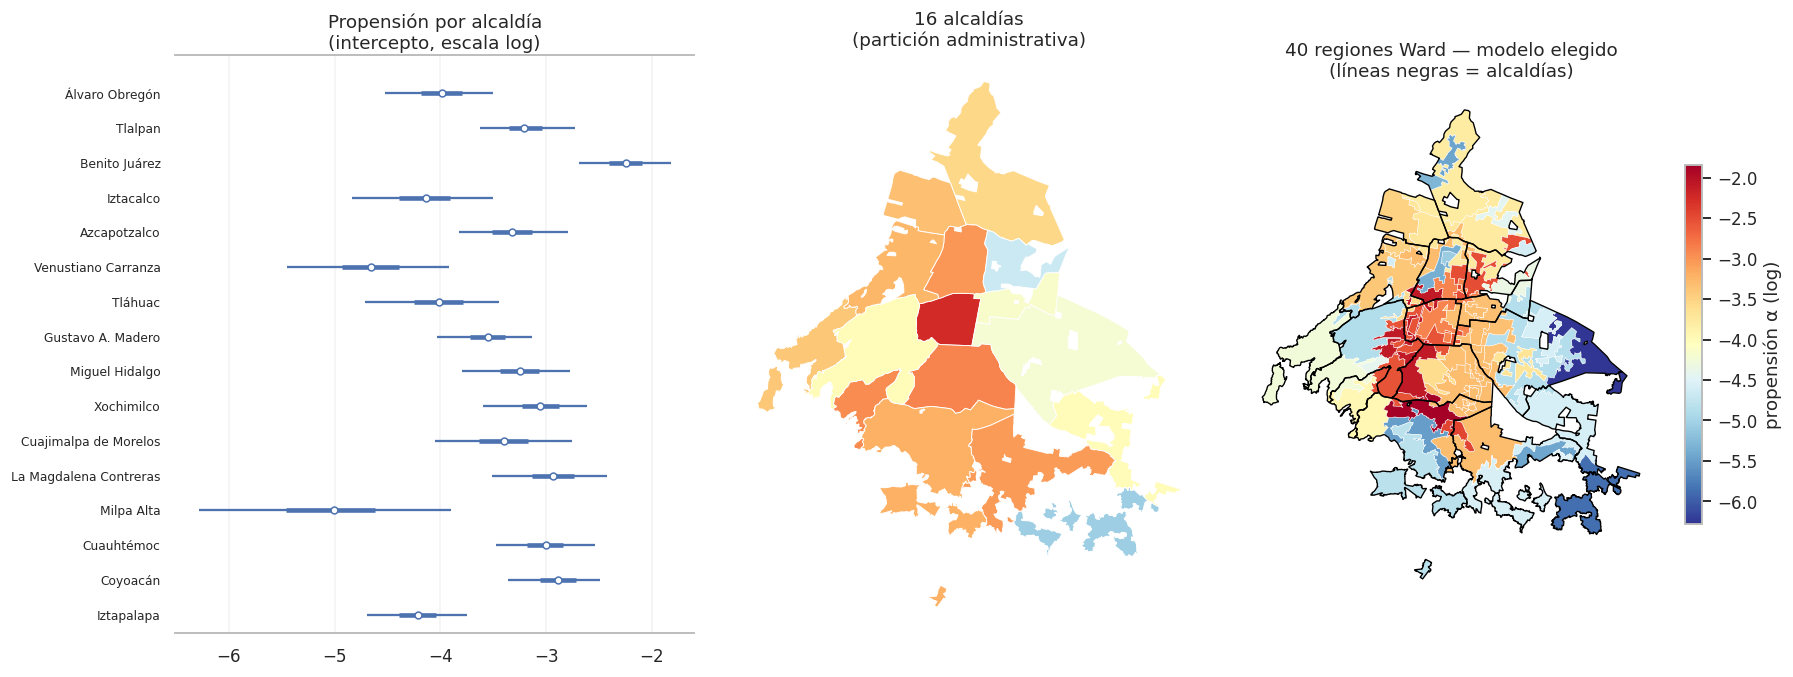

regiones que cruzan más de una alcaldía: 26 de 40
alcaldías partidas en más regiones: {'Iztapalapa': 10, 'Cuauhtémoc': 9, 'Gustavo A. Madero': 9, 'Miguel Hidalgo': 9}


In [6]:
a_reg = az.summary(idata, var_names=["alpha"]); a_reg.index = regs
mapa_reg = mod[["region", "geometry"]].dissolve(by="region")
mapa_reg["alpha"] = a_reg["mean"]
mapa_alc = mod[["nom_mun", "geometry"]].dissolve(by="nom_mun")
mapa_alc["alpha"] = pd.Series(az.summary(idata_alc, var_names=["alpha"])["mean"].values, index=muns)

fig = plt.figure(figsize=(16.5, 6.2))
ax = [fig.add_subplot(1, 3, 1), fig.add_subplot(1, 3, 2), fig.add_subplot(1, 3, 3)]
az.plot_forest(idata_alc, var_names=["alpha"], combined=True, ax=ax[0])
ax[0].set_yticklabels(list(muns)[::-1], fontsize=8)
ax[0].set_title("Propensión por alcaldía\n(intercepto, escala log)")

vmin = min(mapa_reg.alpha.min(), mapa_alc.alpha.min())
vmax = max(mapa_reg.alpha.max(), mapa_alc.alpha.max())
mapa_alc.plot(column="alpha", cmap="RdYlBu_r", vmin=vmin, vmax=vmax, ax=ax[1],
              edgecolor="white", linewidth=.6)
ax[1].set_title("16 alcaldías\n(partición administrativa)"); ax[1].set_axis_off()
mapa_reg.plot(column="alpha", cmap="RdYlBu_r", vmin=vmin, vmax=vmax, ax=ax[2], legend=True,
              edgecolor="white", linewidth=.3,
              legend_kwds={"shrink": .62, "label": "propensión α (log)"})
mapa_alc.boundary.plot(ax=ax[2], color="black", linewidth=.9)
ax[2].set_title("40 regiones Ward — modelo elegido\n(líneas negras = alcaldías)"); ax[2].set_axis_off()
plt.tight_layout(); plt.savefig(FIG/"jerarquico.png", dpi=150, bbox_inches="tight"); plt.show()

cruce = mod.groupby("region").nom_mun.nunique()
print(f"regiones que cruzan más de una alcaldía: {(cruce > 1).sum()} de {len(cruce)}")
print("alcaldías partidas en más regiones:",
      mod.groupby("nom_mun").region.nunique().sort_values(ascending=False).head(4).to_dict())

**σ_α está claramente lejos de cero en las dos versiones** (1.19 con regiones Ward, 0.81 con
alcaldías): hay heterogeneidad territorial real que ni la población ni el área explican.

**Cómo se lee esta figura, que es donde aparece el resultado de la inferencia.**

El panel de la izquierda no muestra un número por alcaldía: muestra la **distribución posterior
completa** del intercepto de cada una. El punto es la media, la barra gruesa el 50% central y la
delgada el 94%. **El ancho de la barra es parte del resultado, no un adorno** — dice cuánta evidencia
hay detrás de cada estimación.

Cuatro cosas concretas que se ven ahí y que no se verían en una tabla de tasas crudas:

- **Benito Juárez arriba, con la barra más angosta:** α = −2.25, intervalo [−2.69, −1.82]. Tiene 102
  AGEBs y 14 asilos, así que el modelo la estima con precisión. Su propensión, exp(α), es 0.105 asilos
  esperados en un AGEB promedio.
- **Milpa Alta abajo, con la barra más ancha de todas:** α = −5.06, intervalo [−6.29, −3.90]. Tiene
  cero asilos observados, y aquí está la gracia del *partial pooling*: el modelo **no le asigna cero**
  —que sería absurdo y además rompería la escala logarítmica— sino una propensión baja y muy incierta.
  Con 42 AGEBs no hay con qué afinarla más. Venustiano Carranza también tiene cero asilos, pero con 147
  AGEBs su barra sale bastante más angosta: **más territorio observado sin un solo establecimiento es
  más evidencia de que la tasa es realmente baja.**
- **El encogimiento en acción:** Cuajimalpa tiene la **tasa cruda más alta de la ciudad** (0.196 asilos
  por cada mil personas de 60+), pero en el modelo queda a media tabla. Son 5 asilos en 31 AGEBs —
  evidencia delgada— así que se jala hacia el promedio de la ciudad. Eso es exactamente lo que uno
  quiere: que una tasa alta calculada sobre pocos casos no se tome al pie de la letra.
- **Y la advertencia:** casi todas las barras se traslapan. Lo que la figura autoriza a decir es que
  **Benito Juárez está por encima del grupo de abajo** —Iztapalapa, Iztacalco, Venustiano Carranza,
  Milpa Alta— pero **no** a ordenar con confianza las alcaldías del medio entre sí.

Los dos mapas son la misma cantidad, en la misma escala de color, sobre dos particiones distintas. El
de en medio pinta cada alcaldía con su intercepto; el de la derecha, cada una de las 40 regiones Ward,
con las fronteras de alcaldía encima en negro para poder comparar.

**La comparación es el argumento de la sección.** La mancha roja del mapa derecho —las zonas de mayor
propensión— atraviesa en diagonal las fronteras negras sin respetarlas: **26 de las 40 regiones cruzan
más de una alcaldía**. Y el contraste interno es enorme donde el promedio administrativo lo escondía:
dentro de Iztapalapa los interceptos de sus diez regiones van de −6.28 a −2.54, un rango de 3.73 en
escala logarítmica, que son **más de 40 veces** de diferencia en propensión entre su zona más y menos
dotada. Azcapotzalco, en cambio, es casi homogénea (rango de 0.29, apenas 1.3 veces).

Por eso k=40 predice mejor que 16, y no por tener más parámetros: **los límites caen donde de verdad
cambia el comportamiento del mercado** —el borde entre colonia consolidada y periferia— en lugar de
donde lo decidió la geografía política. Y por eso la alcaldía se conserva como lectura: el presupuesto
se decide por alcaldía aunque el mercado no se comporte así.

### 3.2.1 Proyección a 2026, 2027, 2029 y 2031

Se aplica la binomial negativa a la población proyectada, propagando la incertidumbre de los parámetros
(intervalo `par_`) y además la variación muestral del propio conteo (intervalo `pred_`, el relevante
para pronosticar: un conteo es aleatorio aunque se conozca μ perfectamente).

In [7]:
rng = np.random.default_rng(SEMILLA); S = 8000
coefs = rng.multivariate_normal(nb.params.values, nb.cov_params().values, S)
n_r = 1/ALPHA
NOM = list(nb.params.index)
i_int, i_p, i_a = NOM.index("Intercept"), NOM.index("lp60"), NOM.index("larea")
i_ult = NOM.index(f"C(anio)[T.{ANIOS_OF[-1]}]")     # se proyecta desde el nivel del último corte
larea_v = mod.larea.values
ANIOS_PRED = [(2026, 6), (2027, 7), (2029, 9), (2031, 11)]

def proyectar(esc, h):
    p_fut = mod.p60_2020.values*(1 + mod.cvegeo.map(ESCENARIOS[esc]).fillna(0).values)**h
    mu = np.exp(coefs[:, i_int][None, :] + coefs[:, i_p][None, :]*np.log(p_fut)[:, None]
                + coefs[:, i_a][None, :]*larea_v[:, None] + coefs[:, i_ult][None, :])
    return p_fut, mu.sum(axis=0), rng.negative_binomial(n_r, n_r/(n_r + mu)).sum(axis=0)

filas = []
for esc in ESCENARIOS:
    for anio, h in ANIOS_PRED:
        p_fut, tot_par, tot_pred = proyectar(esc, h)
        filas.append(dict(escenario=esc, anio=anio, pob60=p_fut.sum(), esperados=tot_par.mean(),
                          par_lo=np.percentile(tot_par, 5), par_hi=np.percentile(tot_par, 95),
                          pred_lo=np.percentile(tot_pred, 5), pred_hi=np.percentile(tot_pred, 95)))
print(pd.DataFrame(filas).round(1).to_string(index=False))

_, ajuste25, _ = proyectar("medio", 5)
print(f"\nCalibración — ajuste para {ANIOS_OF[-1]}: {ajuste25.mean():.0f} asilos "
      f"contra {ofer[ANIOS_OF[-1]].sum():.0f} observados")
p31, _, tp = proyectar("medio", 11)
A_HOY = ofer[ANIOS_OF[-1]].sum()
print(f"P(total 2031 > {A_HOY:.0f}, el nivel de hoy) = {(tp > A_HOY).mean():.3f}")

# cruce con el jerárquico (Ward k=40)
post = idata.posterior
al = post.alpha.stack(m=("chain", "draw")).values
be = post.beta.stack(m=("chain", "draw")).values
ga = post.gamma.stack(m=("chain", "draw")).values
ta = post.tau.stack(m=("chain", "draw")).values[list(pd.factorize(pnl.anio)[1]).index(ANIOS_OF[-1])]
gi = pd.factorize(mod.region)[0]
mu_j = np.exp(al[gi] + be[None, :]*(np.log(p31) - pnl.lp60.mean())[:, None]
              + ga[None, :]*(larea_v - pnl.larea.mean())[:, None] + ta[None, :])
tot_j = rng.poisson(mu_j).sum(axis=0)
print(f"\nJerárquico (Ward k=40) para 2031: {tot_j.mean():.0f} asilos "
      f"[{np.percentile(tot_j, 5):.0f}, {np.percentile(tot_j, 95):.0f}]")
print(f"Binomial negativa para 2031    : {tp.mean():.0f} asilos "
      f"[{np.percentile(tp, 5):.0f}, {np.percentile(tp, 95):.0f}]")

escenario  anio     pob60  esperados  par_lo  par_hi  pred_lo  pred_hi
     bajo  2026 1804177.8      110.8    92.5   131.5     84.0    140.0
     bajo  2027 1864615.5      112.7    94.2   133.8     86.0    142.0
     bajo  2029 1992838.2      116.8    97.6   139.2     90.0    148.0
     bajo  2031 2131627.4      121.2   100.6   144.9     92.0    154.0
    medio  2026 1853423.6      112.2    93.8   133.2     86.0    141.0
    medio  2027 1923999.2      114.5    95.7   135.9     88.0    145.0
    medio  2029 2074457.9      119.2    99.3   142.0     91.0    151.0
    medio  2031 2238364.8      124.1   102.6   149.1     95.0    157.0
     alto  2026 1904349.0      113.7    95.1   135.0     87.0    143.0
     alto  2027 1985830.0      116.3    97.1   138.4     89.0    147.0
     alto  2029 2160627.6      121.6   100.9   145.4     93.0    154.0
     alto  2031 2352656.8      127.2   104.7   153.9     97.0    162.0



Calibración — ajuste para 2025: 110 asilos contra 109 observados


P(total 2031 > 109, el nivel de hoy) = 0.771



Jerárquico (Ward k=40) para 2031: 122 asilos [97, 149]
Binomial negativa para 2031    : 124 asilos [95, 158]


**124 asilos esperados en 2031, con intervalo predictivo al 90% de [95, 157]**, contra 109 hoy. En los
cortes intermedios: **112 en 2026 [86, 141]**, **114 en 2027 [88, 145]** y **119 en 2029 [91, 151]**.
Unos 15 asilos más en seis años mientras la población mayor crece 25% — consecuencia directa de que la
elasticidad sea 0.51 y no 1.

**El ancla es el último corte:** la proyección parte del nivel realmente observado en 2025 y deja que
la población sea lo único que mueva la cifra. La celda imprime la verificación — el modelo reproduce
110 contra 109 observados.

El jerárquico llega a **122 [97, 149]** por un camino completamente distinto: otra verosimilitud, otra
estructura territorial y otro método de estimación. Que dos especificaciones independientes caigan a dos
asilos de distancia es la mejor señal de robustez que tiene este análisis.

Lo único que se afirma con confianza es la dirección. La magnitud exacta, no — y la descomposición de
varianza del notebook detallado dice por qué: **54% de la incertidumbre viene de los parámetros del
modelo de oferta, 46% de la aleatoriedad del conteo y apenas 2% del escenario demográfico**. Afinar la proyección de población no mejoraría el pronóstico de servicios; lo que lo
mejoraría es más información sobre la oferta.

### 3.3 El crecimiento, en una gráfica

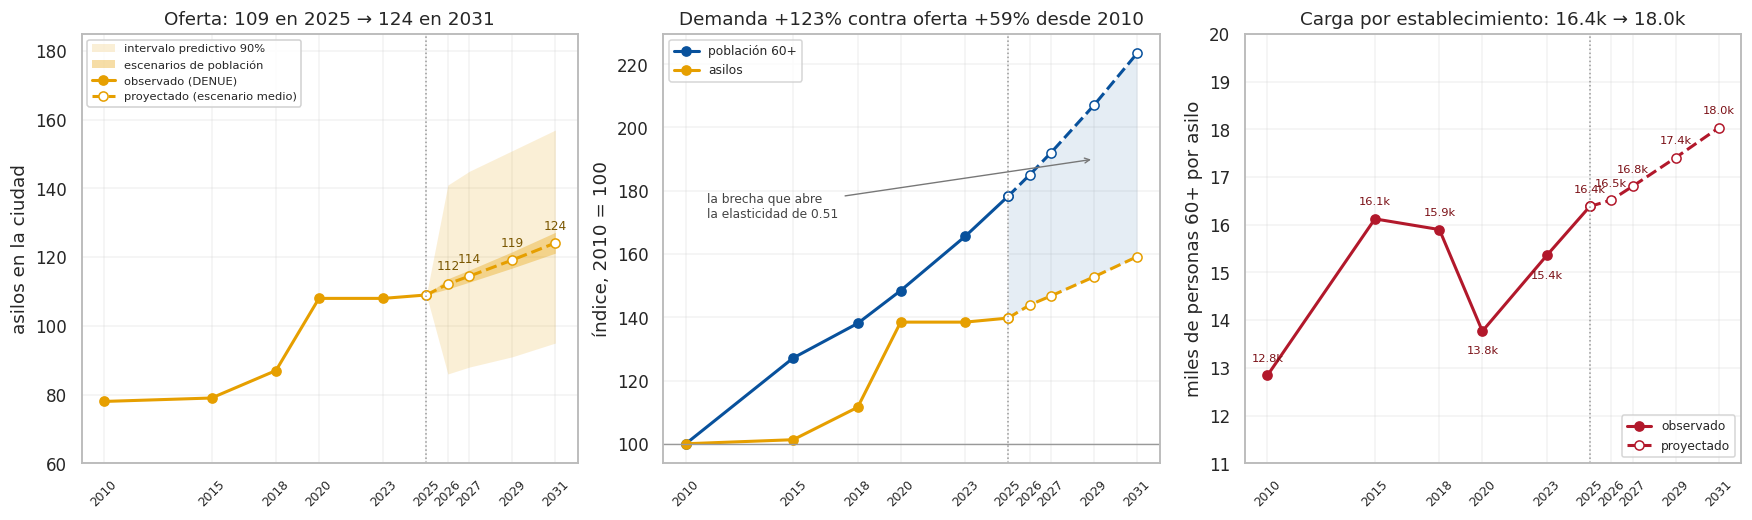

In [8]:
hist_a = ofer.sum()
pob_obs = panel.groupby("anio")["p60"].sum()
hist_p = pd.Series({a: pob_obs[a] if a in pob_obs.index
                    else (mod.p60_2020.values*(1 + r_med)**(a - 2020)).sum() for a in ANIOS_OF})
pr = pd.DataFrame(filas)
med = pr[pr.escenario == "medio"].set_index("anio")
baj = pr[pr.escenario == "bajo"].set_index("anio")
alt = pr[pr.escenario == "alto"].set_index("anio")
AH, AF = list(ANIOS_OF), [a for a, _ in ANIOS_PRED]
ULT = ANIOS_OF[-1]; PTE, A0 = [ULT] + AF, hist_a[ULT]
AZ, NJ, GR, RJ = "#08519C", "#E69F00", "#999999", "#B2182B"

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
a = ax[0]
a.fill_between(PTE, [A0] + list(med.pred_lo), [A0] + list(med.pred_hi), color=NJ, alpha=.16,
               lw=0, label="intervalo predictivo 90%")
a.fill_between(PTE, [A0] + list(baj.esperados), [A0] + list(alt.esperados), color=NJ, alpha=.35,
               lw=0, label="escenarios de población")
a.plot(AH, hist_a.values, "o-", color=NJ, lw=2, ms=6, label="observado (DENUE)")
a.plot(PTE, [A0] + list(med.esperados), "o--", color=NJ, lw=2, ms=6, mfc="white",
       label="proyectado (escenario medio)")
for x_ in AF:
    a.annotate(f"{med.loc[x_, 'esperados']:.0f}", (x_, med.loc[x_, "esperados"]),
               textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8, color="#7A5600")
a.axvline(ULT, color=GR, ls=":", lw=1)
a.set(ylabel="asilos en la ciudad", xticks=AH + AF, ylim=(60, 185),
      title=f"Oferta: {A0:.0f} en {ULT} → {med.loc[2031, 'esperados']:.0f} en 2031")
a.legend(fontsize=7.5, loc="upper left", framealpha=.9)

b = ax[1]
b.plot(AH, 100*hist_p.values/hist_p[2010], "o-", color=AZ, lw=2, ms=6, label="población 60+")
b.plot(PTE, 100*np.r_[hist_p[ULT], med.pob60.values]/hist_p[2010], "o--", color=AZ, lw=2, ms=6,
       mfc="white")
b.plot(AH, 100*hist_a.values/hist_a[2010], "o-", color=NJ, lw=2, ms=6, label="asilos")
b.plot(PTE, 100*np.r_[A0, med.esperados.values]/hist_a[2010], "o--", color=NJ, lw=2, ms=6, mfc="white")
b.fill_between(PTE, 100*np.r_[A0, med.esperados.values]/hist_a[2010],
               100*np.r_[hist_p[ULT], med.pob60.values]/hist_p[2010], color=AZ, alpha=.10, lw=0)
b.annotate("la brecha que abre\nla elasticidad de 0.51", xy=(2029, 190), xytext=(2011, 175),
           fontsize=8, color="#444", ha="left", va="center",
           arrowprops=dict(arrowstyle="->", color="#777", lw=.9))
b.axhline(100, color=GR, lw=.9); b.axvline(ULT, color=GR, ls=":", lw=1)
b.set(ylabel="índice, 2010 = 100", xticks=AH + AF,
      title=f"Demanda +{100*(med.loc[2031,'pob60']/hist_p[2010]-1):.0f}% contra "
            f"oferta +{100*(med.loc[2031,'esperados']/hist_a[2010]-1):.0f}% desde 2010")
b.legend(fontsize=8, loc="upper left")

c = ax[2]
carga_h, carga_f = hist_p.values/hist_a.values, med.pob60.values/med.esperados.values
c.plot(AH, carga_h/1000, "o-", color=RJ, lw=2, ms=6, label="observado")
c.plot(PTE, np.r_[carga_h[-1], carga_f]/1000, "o--", color=RJ, lw=2, ms=6, mfc="white",
       label="proyectado")
for x_, y_ in zip(AH + AF, np.r_[carga_h, carga_f]/1000):
    c.annotate(f"{y_:.1f}k", (x_, y_), textcoords="offset points",
               xytext=(0, -15 if x_ in (2020, 2023) else 9), ha="center", fontsize=7.5,
               color="#7B1016")
c.axvline(ULT, color=GR, ls=":", lw=1)
c.set(ylabel="miles de personas 60+ por asilo", xticks=AH + AF, ylim=(11, 20),
      title=f"Carga por establecimiento: {carga_h[-1]/1000:.1f}k → {carga_f[-1]/1000:.1f}k")
c.legend(fontsize=8, loc="lower right")

for a_ in ax:
    a_.tick_params(axis="x", labelsize=8)
    for t_ in a_.get_xticklabels(): t_.set_rotation(45)
plt.tight_layout(); plt.savefig(FIG/"crecimiento_prediccion.png", dpi=150, bbox_inches="tight")
plt.show()

El panel de en medio es el resumen del análisis: las dos curvas salen del mismo punto en 2010 y se
separan cada año. No es un pronóstico pesimista, es aritmética — es lo que significa que β sea 0.51.

El tercero lo traduce a la unidad que importa: **de 16.4 mil personas de 60 y más por asilo en 2025 a
unas 18 mil en 2031**. Y la serie observada es lo más elocuente: 12.8 mil en 2010, 16.1 mil en 2015,
13.8 mil en 2020 tras el salto de oferta, y de vuelta a 16.4 mil en 2025. **El deterioro no es una
proyección: ya ocurrió dos veces.**

En el primer panel, la franja oscura son los tres escenarios de población y la clara el intervalo
predictivo completo. Que la oscura sea tan delgada es la descomposición de varianza dibujada.

## 4. ¿Dónde está el desajuste?

La sección 3 dice cuántos asilos habrá; ésta dice **cómo se reparte esa oferta frente a dónde crece la
demanda**.

**Una aclaración que decide el método.** Un asilo no es un servicio al que uno va y regresa: **es un
lugar donde uno se queda**. Quien entra a un asilo en Coyoacán viniendo de Iztapalapa ya no vive en
Iztapalapa. Eso descarta los métodos de área de captación tipo 2SFCA, diseñados para clínicas y
farmacias. Se probaron y se descartaron: con radio de 2 km salían 740 AGEBs sin cobertura y con 5 km
salían 69, y el orden de las alcaldías se volteaba. El radio es la definición de qué cuenta como
accesible, no un parámetro que se afine.

Lo que sí se mide sin umbral es **la aritmética del desajuste**. Y lo que estos datos **no** pueden
contestar es si alguien conseguirá cama: eso depende de la capacidad total, y **el DENUE no trae
camas** — un asilo de 8 pesa igual que uno de 80.

### 4.1 La aritmética del desajuste

In [9]:
terr = mod.copy()
terr["p60_2031"] = p31
terr["asilos"] = terr.asilos_2025                 # oferta vigente: último corte del DENUE

T = terr.groupby("nom_mun").agg(p60_2020=("p60_2020", "sum"), p60_2031=("p60_2031", "sum"),
                                asilos=("asilos", "sum"))
T["nuevos"] = T.p60_2031 - T.p60_2020
T["crec_%"] = 100*(T.p60_2031/T.p60_2020 - 1)
T["por_10mil_2025"] = 1e4*T.asilos/T.p60_2020
T["por_10mil_2031"] = 1e4*T.asilos/T.p60_2031
T["nuevos_por_asilo"] = np.where(T.asilos > 0, T.nuevos/T.asilos, np.nan)
T["pers_por_asilo_2031"] = np.where(T.asilos > 0, T.p60_2031/T.asilos, np.nan)
print(T.sort_values("nuevos_por_asilo", ascending=False).round(1).to_string())
c = T.dropna()
print(f"\nCiudad: {T.nuevos.sum():,.0f} personas de 60+ nuevas entre 2020 y 2031 sobre "
      f"{T.asilos.sum():.0f} asilos = {T.nuevos.sum()/T.asilos.sum():,.0f} por establecimiento")
print(f"Oferta por 10 mil personas de 60+: {1e4*T.asilos.sum()/T.p60_2020.sum():.2f} hoy → "
      f"{1e4*T.asilos.sum()/T.p60_2031.sum():.2f} en 2031")
print(f"Desigualdad: {c.nuevos_por_asilo.max()/c.nuevos_por_asilo.min():.1f}x en demanda nueva por "
      f"asilo | {c.pers_por_asilo_2031.max()/c.pers_por_asilo_2031.min():.1f}x en carga a 2031")
print(f"Sin un solo establecimiento: {', '.join(T.index[T.asilos == 0])}")
T.round(2).to_csv("desajuste_por_alcaldia.csv")

                        p60_2020  p60_2031  asilos    nuevos  crec_%  por_10mil_2025  por_10mil_2031  nuevos_por_asilo  pers_por_asilo_2031
nom_mun                                                                                                                                    
Iztacalco                70906.0  107351.2       2   36445.2    51.4             0.3             0.2           18222.6              53675.6
Tláhuac                  45684.0   81212.1       2   35528.1    77.8             0.4             0.2           17764.0              40606.0
Iztapalapa              262062.0  410251.4      10  148189.4    56.5             0.4             0.2           14818.9              41025.1
Venustiano Carranza      78964.0  107134.0       2   28170.0    35.7             0.3             0.2           14085.0              53567.0
Cuajimalpa de Morelos    25458.0   50875.4       3   25417.4    99.8             1.2             0.6            8472.5              16958.5
Azcapotzalco        

**752 mil personas de 60 y más nuevas entre 2020 y 2031, repartidas entre 108 establecimientos: casi
7 mil nuevas por cada asilo que ya existe.** Iztacalco, Tláhuac, Iztapalapa y Venustiano Carranza
reciben entre 14 y 18 mil por asilo existente, contra 2,758 de Benito Juárez — **6.6 veces de
diferencia**, sin que intervenga ninguna definición de distancia. Milpa Alta suma 12 mil personas
mayores sobre **cero** establecimientos.

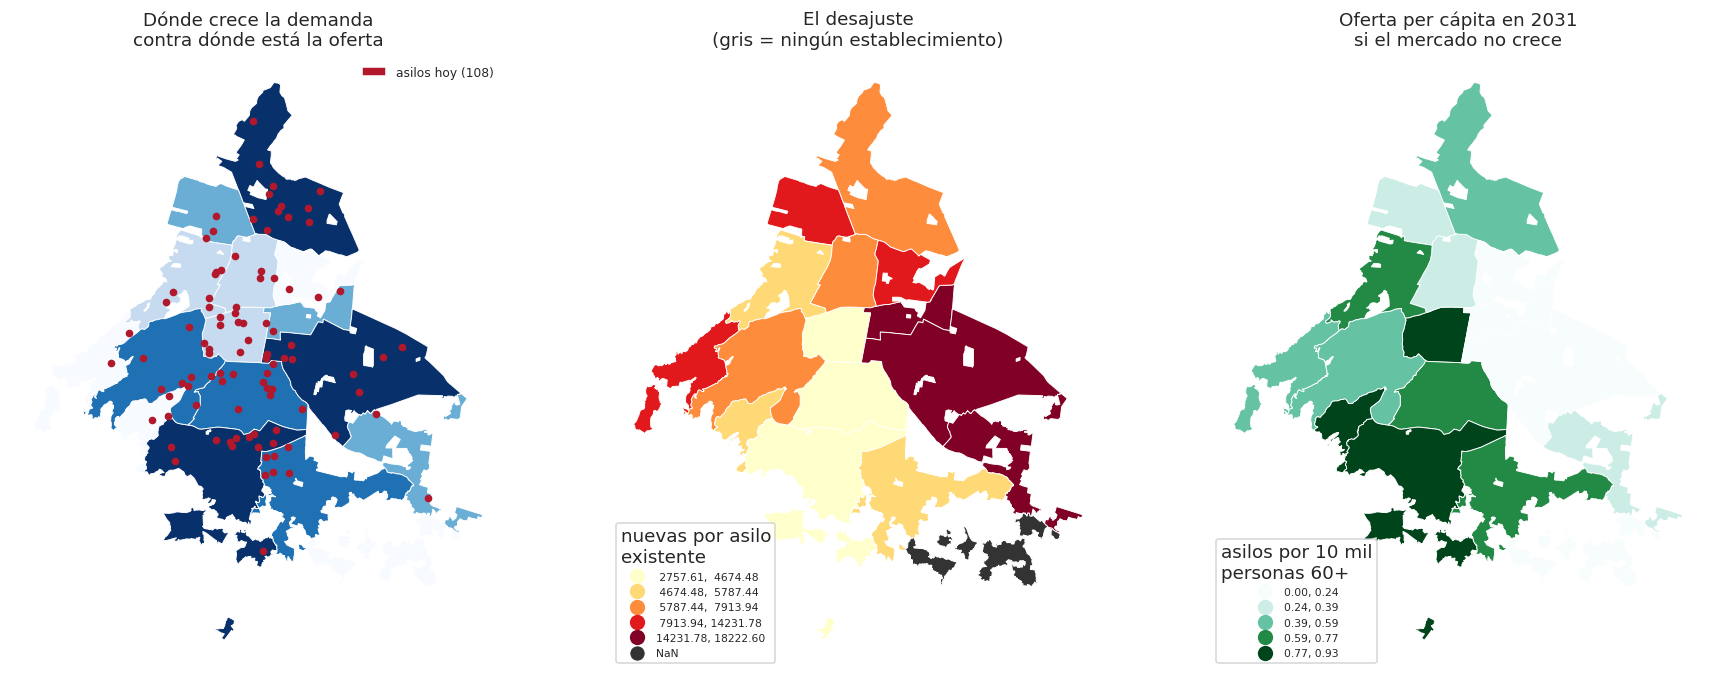

In [10]:
mapa_t = terr[["nom_mun", "geometry"]].dissolve(by="nom_mun").join(T)
fig, ax = plt.subplots(1, 3, figsize=(16.5, 6.2))
mapa_t.plot(column="nuevos", cmap="Blues", scheme="quantiles", k=5, ax=ax[0], legend=True,
            edgecolor="white", linewidth=.6,
            legend_kwds={"fontsize": 7, "loc": "lower left", "title": "personas 60+ nuevas\n2020→2031"})
terr[terr.asilos > 0].centroid.plot(ax=ax[0], color="#B2182B", markersize=16)
ax[0].legend(handles=[Patch(facecolor="#B2182B", label=f"asilos hoy ({int(T.asilos.sum())})")],
             loc="upper right", frameon=False, fontsize=8)
ax[0].set_title("Dónde crece la demanda\ncontra dónde está la oferta")
mapa_t.plot(column="nuevos_por_asilo", cmap="YlOrRd", scheme="quantiles", k=5, ax=ax[1], legend=True,
            edgecolor="white", linewidth=.6, missing_kwds={"color": "#333333"},
            legend_kwds={"fontsize": 7, "loc": "lower left", "title": "nuevas por asilo\nexistente"})
ax[1].set_title("El desajuste\n(gris = ningún establecimiento)")
mapa_t.plot(column="por_10mil_2031", cmap="BuGn", scheme="quantiles", k=5, ax=ax[2], legend=True,
            edgecolor="white", linewidth=.6,
            legend_kwds={"fontsize": 7, "loc": "lower left", "title": "asilos por 10 mil\npersonas 60+"})
ax[2].set_title("Oferta per cápita en 2031\nsi el mercado no crece")
for a_ in ax: a_.set_axis_off()
plt.tight_layout(); plt.savefig(FIG/"desajuste_territorial.png", dpi=150, bbox_inches="tight"); plt.show()

El primer mapa es el análisis entero en una imagen: los puntos rojos se apiñan en el centro-poniente
mientras el azul oscuro —las personas que se suman en la década— se concentra en Iztapalapa y la
periferia sur y oriente. **La oferta está donde estuvo la demanda, no donde va a estar.**

**Qué es y qué no es esta sección.** Contesta *dónde se está acumulando demanda nueva sobre la oferta
que ya existe*. No contesta *dónde debería abrirse un asilo*: para eso harían falta el número de camas
de cada establecimiento, un estándar normativo de camas por cada mil adultos mayores, y los costos de
suelo y personal por zona. Es **el insumo priorizado para esa decisión, no la decisión**, y a nivel de
alcaldía, no de esquina.

## 5. Conclusiones y limitaciones

**Lo que se sostiene:**

1. La población de 60+ creció 48% en una década y crecerá 43-58% más hacia 2031, concentrando el
   crecimiento en la periferia sur y poniente. Validado en backtest (R² 0.94, MAPE 10%). **La oferta,
   en cambio, se detuvo:** 108 asilos en 2020 y 109 en 2025.
2. La elasticidad oferta-población es 0.51 [0.10, 0.92], menor que 1: **la oferta crece a la mitad del
   ritmo de la demanda demográfica**. Estimada sobre los seis cortes del DENUE, con efectos por corte y
   errores agrupados por AGEB. Se proyectan 124 asilos para 2031 [95, 157] contra 109 hoy, y el
   jerárquico coincide con 122 [97, 149].
3. Hay heterogeneidad territorial real más allá de población y área (σ_α > 0), en dirección
   socioeconómica. El nivel de agrupación no se eligió a ojo: Ward k=40 gana la validación cruzada
   espacial contra alcaldías y contra particiones más finas.
4. **El desajuste territorial, sin supuestos de distancia:** 752 mil personas de 60+ nuevas entre 2020
   y 2031 sobre 108 establecimientos —casi 7 mil por asilo existente— con 6.6x de diferencia entre
   alcaldías. Milpa Alta suma 12 mil sobre cero establecimientos.
5. La oferta per cápita de la ciudad pasa de **0.73 a 0.48 asilos por cada diez mil personas de 60+**,
   con 5.5x de desigualdad entre alcaldías y dos en cero.

**Lo que no se sostiene, y conviene decirlo antes de que alguien lo pida:**

- **Predecir cuántos asilos habrá en un AGEB específico.** El poder predictivo a ese nivel es débil y el
  techo alcanzable con estas covariables es apenas 13% del rango entre no saber nada y predecir
  perfecto.
- **Medir acceso individual a un asilo.** Es un servicio residencial: los métodos de área de captación
  no aplican, y por eso se descartaron.
- **Decir cuántos asilos "deberían" existir, o si alguien conseguirá cama.** No hay norma de camas por
  cada mil adultos mayores, y **el DENUE no trae capacidad**.
- **Afirmar hacia dónde se mueve el mercado.** Las aperturas netas por alcaldía 2010-2025 no muestran
  patrón significativo en ninguna dirección (detalle en el notebook completo).
- **Decir dónde *debería* abrir un asilo.** La sección 4 da el insumo priorizado, no la decisión.
- **Poner una cifra precisa al total.** El intervalo para 2031 sigue midiendo más de 60 asilos.
- **Cualquier afirmación sobre enfermería a domicilio.**
- **Leer la proyección como necesidad.** Es "cuántos habrá si nada cambia", no "cuántos se necesitan".

**Limitaciones de los datos:** 2015 es estimación de encuesta con error de muestreo propio; **los cortes
del DENUE no son plenamente comparables** —el salto de 2018 a 2020 y la quietud de 2020 a 2023 apuntan
a reclasificación, que el modelo absorbe con efectos por corte—; las proyecciones usan tasas observadas en vez de anclarse a
CONAPO —aunque la descomposición de varianza muestra que eso cambiaría poco—; y **faltan covariables
socioeconómicas**, que es la mejora con mejor relación esfuerzo-beneficio para una siguiente versión: el
patrón territorial apunta con fuerza al ingreso, pero sin el índice de marginación por AGEB eso es
hipótesis y no resultado.

**Siguiente paso natural:** incorporar marginación por AGEB, y pasar de radio euclidiano a tiempos de
traslado por red vial para la accesibilidad.